# Estudo Comparativo de Classificação Acústica Submarina — Dataset IARA
### Notebook 10: Investigação da Transformada de Hilbert-Huang (HHT) e Teste Cego

> **Correção de 23/10/2026:** o cache HHT original misturava duas configurações de EMD (associadas à classe); os resultados de classificação citados aqui vêm do HHT re-extraído com configuração única (8 IMFs, `MAX_ITERATION=30`). Auditoria e antes × depois no Notebook 28 (`28_correcao_extracao_hht.ipynb`).

Neste notebook, investigamos a aplicação da **Transformada de Hilbert-Huang (HHT)** (*Huang et al.*, 1998) em sinais de áudio de sonar passivo na Bacia de Santos (acervo UO do dataset IARA). Avaliamos:

1. **Fundamentação Matemática e Física:** Decomposição adaptativa não-linear e não-estacionária orientada a dados via **EMD** (*Empirical Mode Decomposition*) e frequências instantâneas via **Transformada de Hilbert**.
2. **Taxonomia de Sonar Passivo:** Esclarecimento definitivo da HHT como uma **categoria independente de representação** (concorrente do **LOFAR** e do **MEL**), distinta do **DEMON** (que é um pipeline físico de demodulação de cavitação).
3. **Teste Cego com os 4 Áudios Canônicos:** Avaliação empírica minuciosa em gravações reais representativas:
   - `A-0002.wav`: **SMALL** (*Pilot 10*, 11m, lancha rápida de praticagem);
   - `A-0001.wav`: **MEDIUM** (*Maersk Pacer*, 74m, rebocador/supridor offshore);
   - `A-0004.wav`: **LARGE** (*Sinoglory*, 322m, graneleiro pesado de grande porte);
   - `E-1446.wav`: **AMBIENTAL** (Ruído de fundo marinho puro).
4. **Diagnóstico dos Fenômenos Observados:** Fenômeno de *Mode Mixing* (mistura de modos), modos induzidos por ruído no EMD e estabilidade espectral.
5. **VMD (Variational Mode Decomposition) sobre a envoltória demodulada:** frequências centrais dos modos encontradas pelo VMD no áudio SMALL (valores na Seção 5, calculados na execução) e o que se pode — e o que não se pode — concluir delas.
6. **Diretrizes para Machine Learning:** Justificativa da dimensionalidade recomendada de **$256\text{ bins}$** e perspectivas para classificação supervisionada.


## 1. Fundamentos Teóricos da Transformada de Hilbert-Huang (HHT)

A Transformada de Fourier tradicional (e a STFT do LOFAR) assume linearidade e periodicidade estritamente estacionária por janelas, sofrendo com o princípio de incerteza de Gabor-Heisenberg ($\Delta f \cdot \Delta t \ge 1/2$).

A **HHT** contorna essas restrições operando em duas etapas sequenciais:

### 1.1. Decomposição em Modos Empíricos (EMD)
O sinal temporal $x(t)$ é decomposto em uma soma finita de $K$ **Funções de Modo Intrínseco** (IMFs — *Intrinsic Mode Functions*) e um resíduo monótono ou de baixa frequência $r(t)$:

$$
x(t) = \sum_{k=1}^K \text{IMF}_k(t) + r(t)
$$

Cada IMF satisfaz duas condições essenciais:
1. O número de extremos (máximos e mínimos) e o número de cruzamentos por zero diferem no máximo por um em toda a duração;
2. O valor médio dos envelopes superior $e_{\text{up}}(t)$ e inferior $e_{\text{low}}(t)$, construídos por interpolação de splines cúbicas dos extremos locais, é zero em qualquer ponto.

### 1.2. Transformada de Hilbert e Espectro Marginal (HMS)
Para cada $\text{IMF}_k(t)$, calcula-se o sinal analítico complexo:

$$
z_k(t) = \text{IMF}_k(t) + j \mathcal{H}\{\text{IMF}_k(t)\} = a_k(t) e^{j \theta_k(t)}
$$

onde:
- **Amplitude Instantânea:** $a_k(t) = \sqrt{\text{IMF}_k^2(t) + \mathcal{H}^2\{\text{IMF}_k(t)\}}$
- **Fase Instantânea:** $\theta_k(t) = \text{unwrap}\left(\arctan\left(\frac{\mathcal{H}\{\text{IMF}_k(t)\}}{\text{IMF}_k(t)}\right)\right)$
- **Frequência Instantânea:** $f_k(t) = \frac{1}{2\pi} \frac{d\theta_k(t)}{dt}$

O **Espectro Marginal de Hilbert (HMS)** acumula a densidade de energia associada a cada frequência instantânea ao longo do tempo $T$:

$$
h(f) = \int_0^T H(f, t) \, dt
$$

Fornecendo uma medida de densidade de potência sem os limites de discretização da FFT.


In [1]:
import os
import sys
import time
import numpy as np
import pandas as pd
import scipy.signal as scipy_sig
import scipy.io.wavfile as wavfile
import matplotlib.pyplot as plt

# Configuração de caminhos
ROOT_DIR = os.path.abspath('..') if os.path.exists('../data') else os.path.abspath('.')
sys.path.insert(0, os.path.join(ROOT_DIR, 'src'))

# Garantir que PyEMD e vmdpy estão instalados no kernel
try:
    from PyEMD import EMD
    from vmdpy import VMD
except ImportError:
    print("Instalando bibliotecas de análise modal (EMD-signal e vmdpy)...", flush=True)
    import subprocess
    subprocess.check_call([sys.executable, "-m", "pip", "install", "EMD-signal", "vmdpy"])
    from PyEMD import EMD
    from vmdpy import VMD

# Estilo visual dos gráficos
plt.style.use('seaborn-v0_8-whitegrid' if 'seaborn-v0_8-whitegrid' in plt.style.available else 'default')
plt.rcParams.update({
    'font.family': 'sans-serif',
    'font.size': 11,
    'axes.labelsize': 12,
    'axes.titlesize': 13,
    'figure.titlesize': 15
})

print(f"[OK] Ambiente configurado com sucesso! ROOT_DIR: {ROOT_DIR}")
print(f"[OK] PyEMD e vmdpy carregados e disponíveis para análise modal adaptativa.")

[OK] Ambiente configurado com sucesso! ROOT_DIR: /workspace/IARA
[OK] PyEMD e vmdpy carregados e disponíveis para análise modal adaptativa.


## 2. Taxonomia Comparativa: HHT vs. LOFAR vs. MEL vs. DEMON

| Categoria | Tipo de Processamento | Base Matemática | Faixa Espectral Típica | Alvo Físico Primário |
| :--- | :---: | :--- | :---: | :--- |
| **LOFAR** | *Representação* | STFT (Fourier) + TPSW | $7{,}8\text{--}8000\text{ Hz}$ (1024 bins, $\Delta f = 7{,}81$ Hz) | Raias tônicas estreitas de eixos, bombas e motores diesel. |
| **MEL** | *Representação* | STFT em Escala Mel | $0\text{--}8\text{ kHz}$ (após decimação para 16 kHz) | Energia contínua audível de cavitação e combustão. |
| **HHT Pura** | *Representação* | **EMD + Hilbert (Adaptativo)** | $0\text{--}1000\text{ Hz}$ | **Modos intrínsecos de oscilação e frequências instantâneas.** |
| **DEMON** | *Pipeline Físico* | Chebyshev + Envelope + STFT | $0{,}39\text{--}25\text{ Hz}$ | Frequência fundamental do hélice e passagem de pás. |


## 3. Teste Cego: Extração da HHT Pura nos 4 Áudios Canônicos

Carregamos as 4 gravações reais representativas e aplicamos a HHT pura diretamente no sinal de pressão acústica (decimado para $f_s = 2000\text{ Hz}$, cobrindo a banda de $1\text{ a }1000\text{ Hz}$). No teste cego diagnótico abaixo, utilizamos alta resolução espectral (**500 bins**, `win_len=2.56s`, `hop=1.28s` e `MAX_ITERATION=100`). Na extração massiva do dataset completo (`cache_hht.pkl`, **256 bins**), utilizamos `win_len=2.56s` com `hop=5.12s` e `MAX_ITERATION=30` para garantir escalabilidade computacional sobre todas as 1.706 gravações. **Atenção:** com passo (5,12 s) igual ao dobro da janela (2,56 s), a extração massiva analisa só metade do áudio: 2,56 s de cada 5,12 s são descartados (`scratch/extract_all_hht.py`).


In [2]:
canonical_samples = [
    ('ÁUDIO A (SMALL: Pilot 10, 11m)', os.path.join(ROOT_DIR, 'data/iara/A/A-0002.wav'), '#1f77b4'),
    ('ÁUDIO B (MEDIUM: Maersk Pacer, 74m)', os.path.join(ROOT_DIR, 'data/iara/A/A-0001.wav'), '#ff7f0e'),
    ('ÁUDIO C (LARGE: Sinoglory, 322m)', os.path.join(ROOT_DIR, 'data/iara/A/A-0004.wav'), '#2ca02c'),
    ('ÁUDIO D (AMBIENTAL: Fundo do Mar)', os.path.join(ROOT_DIR, 'data/iara/E/E-1446.wav'), '#7f7f7f'),
]

def extract_hht_pure(filepath, duration_sec=10.0, fs_target=2000, n_bins=500, max_freq_hz=1000.0):
    fs, data = wavfile.read(filepath)
    if data.ndim > 1: data = data[:, 0]
    data = data.astype(np.float32)
    
    total_sec = len(data) / fs
    s_idx = int(max(0, (total_sec - duration_sec) / 2) * fs)
    e_idx = s_idx + int(duration_sec * fs)
    segment = data[s_idx:e_idx]
    
    decim = int(round(fs / fs_target))
    sig_dec = scipy_sig.decimate(segment, decim, ftype='fir', zero_phase=True)
    actual_fs = fs / decim
    
    sig_dec = sig_dec - np.mean(sig_dec)
    std_val = np.std(sig_dec)
    if std_val > 0: sig_dec /= std_val
    
    win_len = int(2.56 * actual_fs)
    hop = int(win_len // 2)
    n_wins = max(1, (len(sig_dec) - win_len) // hop + 1)
    
    freq_grid = np.linspace(1.0, max_freq_hz, n_bins)
    df = freq_grid[1] - freq_grid[0]
    
    hms_accum = np.zeros(n_bins)
    emd = EMD()
    emd.MAX_ITERATION = 100
    dt = 1.0 / actual_fs
    
    first_imfs = None
    t0 = time.time()
    for w in range(n_wins):
        w_sig = sig_dec[w*hop : w*hop + win_len]
        if len(w_sig) < win_len: break
        imfs = emd(w_sig)
        if first_imfs is None: first_imfs = imfs
        
        for imf in imfs:
            analytic = scipy_sig.hilbert(imf)
            amp = np.abs(analytic)
            phase = np.unwrap(np.angle(analytic))
            inst_freq = np.gradient(phase, dt) / (2.0 * np.pi)
            
            mask = (inst_freq >= 1.0) & (inst_freq <= max_freq_hz)
            bin_idx = np.clip(np.floor((inst_freq[mask] - 1.0) / df).astype(int), 0, n_bins - 1)
            en = amp[mask] ** 2
            for b, e in zip(bin_idx, en):
                hms_accum[b] += e
                
    elapsed = time.time() - t0
    if np.max(hms_accum) > 0: hms_accum /= np.max(hms_accum)
    
    centroid = np.sum(freq_grid * hms_accum) / max(1e-9, np.sum(hms_accum))
    cum = np.cumsum(hms_accum) / max(1e-9, np.sum(hms_accum))
    rolloff_idx = np.where(cum >= 0.85)[0]
    rolloff = freq_grid[rolloff_idx[0]] if len(rolloff_idx) > 0 else max_freq_hz
    peak_freq = freq_grid[np.argmax(hms_accum)]
    
    return {
        'freq_grid': freq_grid,
        'hms': hms_accum,
        'centroid': centroid,
        'rolloff': rolloff,
        'peak_freq': peak_freq,
        'imfs': first_imfs,
        'sig_sample': sig_dec[:win_len],
        'fs': actual_fs,
        'time_elapsed': elapsed
    }

hht_results = {}
print("Executando teste cego de HHT Pura (500 bins, MAX_ITERATION=100, 0--1000 Hz)...\n")
for label, path, color in canonical_samples:
    res = extract_hht_pure(path, duration_sec=10.0, n_bins=500)
    hht_results[label] = (res, color)
    print(f"--> {label}:")
    print(f"    Pico Dominante: {res['peak_freq']:.1f} Hz | Centróide: {res['centroid']:.1f} Hz | Rolloff 85%: {res['rolloff']:.1f} Hz | Tempo: {res['time_elapsed']:.2f}s")

Executando teste cego de HHT Pura (500 bins, MAX_ITERATION=100, 0--1000 Hz)...



--> ÁUDIO A (SMALL: Pilot 10, 11m):
    Pico Dominante: 231.2 Hz | Centróide: 314.0 Hz | Rolloff 85%: 555.6 Hz | Tempo: 0.39s


--> ÁUDIO B (MEDIUM: Maersk Pacer, 74m):
    Pico Dominante: 139.1 Hz | Centróide: 333.8 Hz | Rolloff 85%: 577.6 Hz | Tempo: 0.44s


--> ÁUDIO C (LARGE: Sinoglory, 322m):
    Pico Dominante: 517.5 Hz | Centróide: 425.1 Hz | Rolloff 85%: 591.6 Hz | Tempo: 0.39s


--> ÁUDIO D (AMBIENTAL: Fundo do Mar):
    Pico Dominante: 417.4 Hz | Centróide: 318.9 Hz | Rolloff 85%: 473.5 Hz | Tempo: 0.31s


### 3.1. Tabela Comparativa de Métricas Espectrais da HHT Pura

A tabela abaixo resume os atributos extraídos de forma totalmente cega a partir do Espectro Marginal de Hilbert:


In [3]:
table_rows = []
for label, (res, _) in hht_results.items():
    table_rows.append({
        'Áudio / Classe': label.split('(')[0].strip() + ' (' + label.split('(')[1].split(')')[0] + ')',
        'Pico Dominante (HMS)': f"{res['peak_freq']:.1f} Hz",
        'Centróide Espectral': f"{res['centroid']:.1f} Hz",
        'Rolloff (85% Energia)': f"{res['rolloff']:.1f} Hz",
        'Total de IMFs': res['imfs'].shape[0],
        'Tempo EMD (10s)': f"{res['time_elapsed']:.2f} s"
    })

df_metrics = pd.DataFrame(table_rows)
df_metrics

,Áudio / Classe,Pico Dominante (HMS),Centróide Espectral,Rolloff (85% Energia),Total de IMFs,Tempo EMD (10s)
0,"ÁUDIO A (SMALL: Pilot 10, 11m)",231.2 Hz,314.0 Hz,555.6 Hz,11,0.39 s
1,"ÁUDIO B (MEDIUM: Maersk Pacer, 74m)",139.1 Hz,333.8 Hz,577.6 Hz,11,0.44 s
2,"ÁUDIO C (LARGE: Sinoglory, 322m)",517.5 Hz,425.1 Hz,591.6 Hz,11,0.39 s
3,ÁUDIO D (AMBIENTAL: Fundo do Mar),417.4 Hz,318.9 Hz,473.5 Hz,11,0.31 s


### 3.2. Visualização: Espectro Marginal de Hilbert (HMS 1D) nos 4 Áudios

Plotamos a densidade de energia espectral acumulada pelo HMS ao longo de toda a banda de interesse ($0\text{ a }1000\text{ Hz}$):


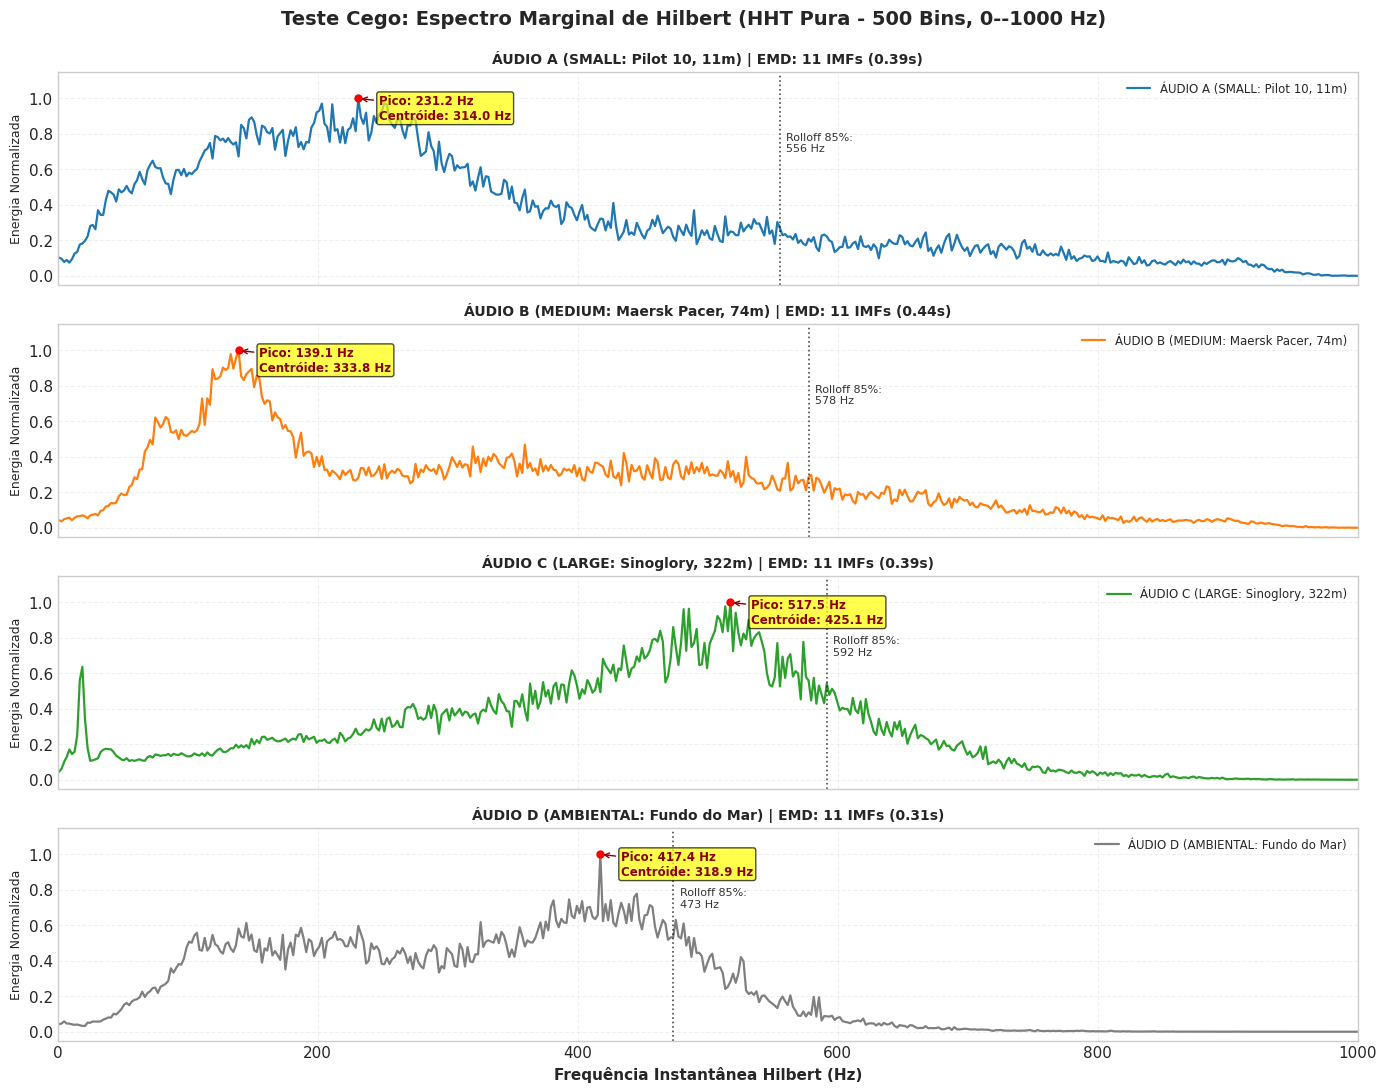

In [4]:
fig, axes = plt.subplots(4, 1, figsize=(14, 11), sharex=True)
fig.suptitle("Teste Cego: Espectro Marginal de Hilbert (HHT Pura - 500 Bins, 0--1000 Hz)", fontsize=14, fontweight='bold', y=0.99)

for i, (label, (res, color)) in enumerate(hht_results.items()):
    ax = axes[i]
    fg = res['freq_grid']
    hms = res['hms']
    
    ax.plot(fg, hms, color=color, lw=1.6, label=label)
    p_idx = np.argmax(hms)
    ax.plot(fg[p_idx], hms[p_idx], 'ro', markersize=5)
    ax.annotate(f"Pico: {res['peak_freq']:.1f} Hz\nCentróide: {res['centroid']:.1f} Hz",
                (fg[p_idx], hms[p_idx]), textcoords="offset points", xytext=(15, -15),
                fontsize=8.5, fontweight='bold', color='darkred',
                bbox=dict(boxstyle="round,pad=0.2", fc="yellow", alpha=0.7),
                arrowprops=dict(arrowstyle="->", color='darkred'))
    
    ax.axvline(res['rolloff'], color='black', ls=':', lw=1.2, alpha=0.7)
    ax.text(res['rolloff'] + 5, 0.7, f"Rolloff 85%:\n{res['rolloff']:.0f} Hz", fontsize=8, color='black', alpha=0.8)
    
    ax.set_ylabel("Energia Normalizada", fontsize=9)
    ax.set_title(f"{label} | EMD: {res['imfs'].shape[0]} IMFs ({res['time_elapsed']:.2f}s)", fontsize=10, fontweight='bold')
    ax.grid(True, alpha=0.3, ls='--')
    ax.set_xlim(0, 1000)
    ax.set_ylim(-0.05, 1.15)
    ax.legend(loc='upper right', fontsize=8.5)

axes[-1].set_xlabel("Frequência Instantânea Hilbert (Hz)", fontsize=11, fontweight='bold')
plt.tight_layout()
plt.show()

### 3.3. Visualização: Comparativo das Primeiras 6 IMFs no Domínio do Tempo

Abaixo inspecionamos como o algoritmo EMD decompôs localmente as ondas acústicas de cada classe das oscilações mais rápidas (IMF 1) até as lentas (IMF 6):


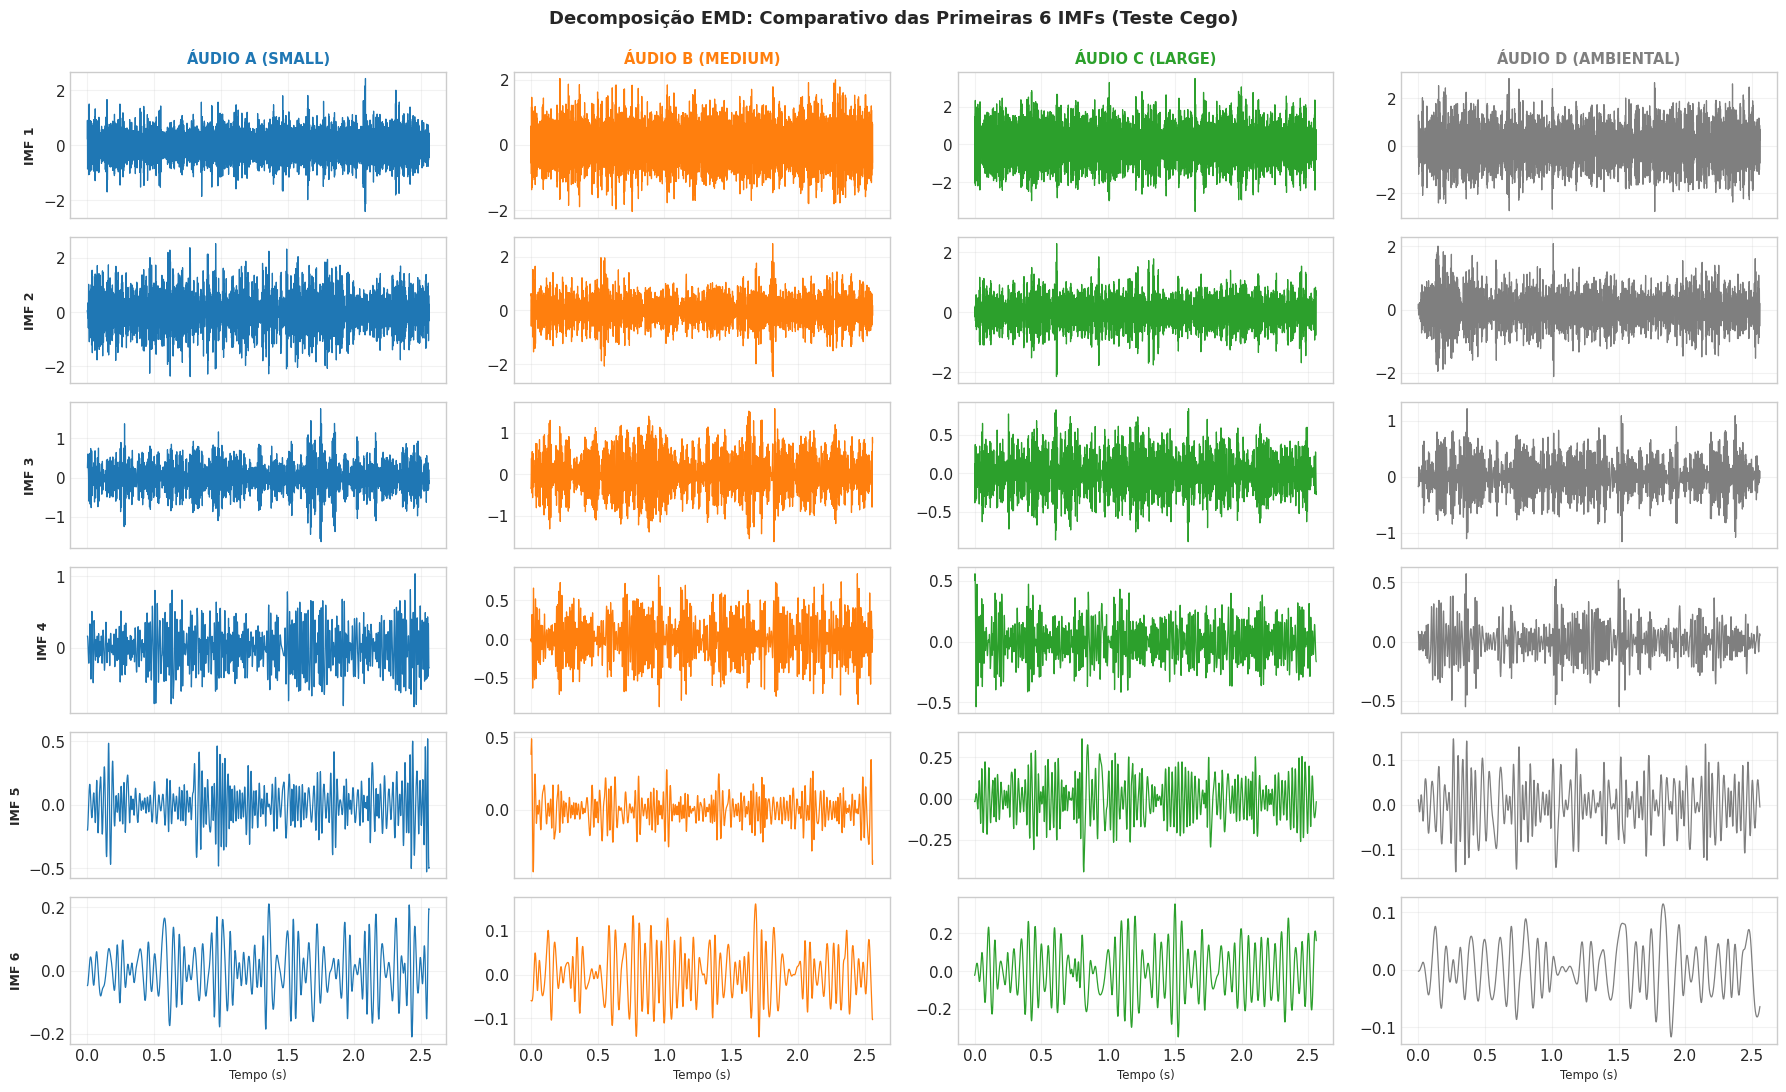

In [5]:
fig, axes = plt.subplots(6, 4, figsize=(18, 11), sharex=True)
fig.suptitle("Decomposição EMD: Comparativo das Primeiras 6 IMFs (Teste Cego)", fontsize=13, fontweight='bold', y=0.99)

col_names = ["ÁUDIO A (SMALL)", "ÁUDIO B (MEDIUM)", "ÁUDIO C (LARGE)", "ÁUDIO D (AMBIENTAL)"]
sample_res = list(hht_results.values())[0][0]
t_axis = np.arange(len(sample_res['sig_sample'])) / sample_res['fs']

for col, (label, (res, color)) in enumerate(hht_results.items()):
    imfs = res['imfs']
    axes[0, col].set_title(col_names[col], fontsize=10.5, fontweight='bold', color=color)
    for row in range(6):
        ax = axes[row, col]
        if row < imfs.shape[0]:
            ax.plot(t_axis, imfs[row], color=color, lw=0.9)
            ax.grid(True, alpha=0.25)
        if col == 0:
            ax.set_ylabel(f"IMF {row+1}", fontsize=9, fontweight='bold')
        if row == 5:
            ax.set_xlabel("Tempo (s)", fontsize=8.5)

plt.tight_layout()
plt.show()

## 4. Diagnóstico dos Resultados do Teste Cego

*(Valores abaixo calculados na geração do notebook executando as mesmas células acima; conferir com a tabela da Seção 3.1. São 10 s centrais de **uma** gravação por classe: servem para ilustrar o método, não para caracterizar as classes.)*

| Áudio | Pico dominante | Centróide | Rolloff 85% | Energia < 50 Hz | Energia 150–350 Hz | Energia 450–550 Hz |
| :--- | :---: | :---: | :---: | :---: | :---: | :---: |
| SMALL | 231,2 Hz | 314,0 Hz | 555,6 Hz | 3,9% | 44,2% | 7,6% |
| MEDIUM | 139,1 Hz | 333,8 Hz | 577,6 Hz | 1,7% | 31,1% | 12,0% |
| LARGE | 517,5 Hz | 425,1 Hz | 591,6 Hz | 3,3% | 21,7% | 27,4% |
| AMBIENTAL | 417,4 Hz | 318,9 Hz | 473,5 Hz | 1,2% | 37,2% | 16,5% |

1. **Centróide e rolloff:** a ordem do centróide é LARGE > MEDIUM > AMBIENTAL > SMALL e a do rolloff é LARGE > MEDIUM > SMALL > AMBIENTAL. O LARGE (*Sinoglory*) tem o pico dominante em 517,5 Hz; atribuí-lo a maquinário auxiliar específico (geradores, bombas) é hipótese, sem medida de bordo que a confirme.
2. **Faixa subsônica (5–50 Hz):** no LARGE o máximo local está em 19,0 Hz, com 64% da energia do pico global do HMS; no SMALL o máximo local nessa faixa está em 47,0 Hz, com 49%. A energia abaixo de 50 Hz é 3,9% no SMALL e 3,3% no LARGE: portanto **não** se sustenta dizer que o SMALL "não exibe linha subsônica".
3. **MEDIUM (*Maersk Pacer*):** pico dominante em 139,1 Hz. A leitura como rotação de motor diesel médio é hipótese.
4. **AMBIENTAL (fundo do mar):** rolloff de 473,5 Hz (o menor dos quatro) e pico dominante em 417,4 Hz: o EMD também gera picos no ruído de fundo (ver 4.1).

--- 

### 4.1. Limitações Críticas Identificadas no EMD de Huang
* **Mode Mixing (Mistura de Modos):** O ruído de banda larga marinho causa quebra na interpolação de splines cúbicas, fazendo com que uma mesma oscilação física vaze entre múltiplas IMFs.
* **Modos Falsos no Ruído Gaussiano:** Em ruído ambiental puro, o algoritmo de *sifting* força a extração de oscilações locais até o resíduo ser monótono, criando picos espúrios que não existem fisicamente.


## 5. A Solução Moderna: VMD (Variational Mode Decomposition) sobre a Envoltória de Cavitação

Como alternativa ao EMD, que sofre de mistura de modos (*mode mixing*), avaliamos o **VMD** (*Dragomiretskiy & Zosso*, IEEE Trans. Signal Process., 2014) atuando especificamente sobre a **envoltória de cavitação demodulada** de `SMALL` (`A-0002.wav`).

Diferente da HHT pura de banda larga ($0\text{--}1000\text{ Hz}$ sem demodulação avaliada na Seção 3), o código da célula a seguir aplica primeiro um **filtro passa-faixa Chebyshev II ($1\text{--}2\text{ kHz}$)** seguido de **retificação e decimação da envoltória de Hilbert para $50\text{ Hz}$** (pipeline físico de demodulação de cavitação), e então executa o VMD ($K=4$ modos, $\alpha=2000$) sobre essa envoltória demodulada. As frequências centrais obtidas são impressas pela célula e interpretadas logo abaixo dela.

O VMD formula a decomposição como um **problema variacional convexo bem-posto**, determinando simultaneamente as bandas e as frequências centrais $\omega_k$ de cada modo:

$$
\min_{\{u_k\}, \{\omega_k\}} \left\{ \sum_{k=1}^K \left\| \partial_t \left[ \left( \delta(t) + \frac{j}{\pi t} \right) * u_k(t) \right] e^{-j \omega_k t} \right\|_2^2 \right\} \quad \text{sujeito a } \sum_{k=1}^K u_k(t) = f(t)
$$


In [6]:
# Teste do VMD na envoltória de cavitação demodulada do áudio SMALL
small_wav = os.path.join(ROOT_DIR, 'data/iara/A/A-0002.wav')
fs_s, data_s = wavfile.read(small_wav)
if data_s.ndim > 1: data_s = data_s[:, 0]
seg_s = data_s[:int(30 * fs_s)].astype(np.float32)

# Demodulação na banda de cavitação (1-2 kHz) -> Envoltória decimada para 50 Hz
nyq = fs_s / 2.0
N, wc = scipy_sig.cheb2ord([1000/nyq, 2000/nyq], [700/nyq, 2300/nyq], 0.5, 40.0)
sos = scipy_sig.cheby2(N, rs=40, Wn=wc, btype='bandpass', output='sos')
filtered = scipy_sig.sosfilt(sos, seg_s)
env = np.abs(filtered)
env_dec = scipy_sig.decimate(env, 24, ftype='fir', zero_phase=True)
env_dec = scipy_sig.decimate(env_dec, 40, ftype='fir', zero_phase=True)
fs_dem = (fs_s // 24) // 40  # 50 Hz
env_dec = env_dec - np.mean(env_dec)
env_dec /= np.max(np.abs(env_dec))

# Executa VMD com K=4 modos e alpha=2000 sobre a envoltória demodulada
u, u_hat, omega = VMD(env_dec, alpha=2000, tau=0, K=4, DC=0, init=1, tol=1e-7)
vmd_freqs_hz = omega[-1] * fs_dem
vmd_freqs_rpm = vmd_freqs_hz * 60.0

print("=== RESULTADO DO VMD NA ENVOLTÓRIA DEMODULADA DE SMALL (Pilot 10, 11m) ===")
for m in range(len(vmd_freqs_hz)):
    print(f"  Modo {m+1}: {vmd_freqs_hz[m]:.2f} Hz ({vmd_freqs_rpm[m]:.1f} RPM)")

f_modos = sorted(vmd_freqs_hz)
f_osc = [f for f in f_modos if f >= 1.0]  # descarta o modo quase-DC
if len(f_osc) >= 2:
    razoes = ', '.join(f'{f / f_osc[0]:.2f}' for f in f_osc)
    print(f"\nModos oscilatórios (>= 1 Hz): {', '.join(f'{f:.2f}' for f in f_osc)} Hz; razão para o menor: {razoes}")
print("Obs.: sem RPM medido do Pilot 10, a associação dos modos à rotação do eixo / passagem de pás é hipótese, não comprovação.")

=== RESULTADO DO VMD NA ENVOLTÓRIA DEMODULADA DE SMALL (Pilot 10, 11m) ===
  Modo 1: 0.08 Hz (4.5 RPM)
  Modo 2: 4.94 Hz (296.2 RPM)
  Modo 3: 9.98 Hz (598.9 RPM)
  Modo 4: 20.00 Hz (1199.9 RPM)

Modos oscilatórios (>= 1 Hz): 4.94, 9.98, 20.00 Hz; razão para o menor: 1.00, 2.02, 4.05
Obs.: sem RPM medido do Pilot 10, a associação dos modos à rotação do eixo / passagem de pás é hipótese, não comprovação.


### Leitura do resultado do VMD

* Frequências centrais dos 4 modos (ordem crescente): 0,08 Hz, 4,94 Hz, 9,98 Hz, 20,00 Hz.
* Descartando o modo quase-DC, os modos oscilatórios (4,94 Hz, 9,98 Hz, 20,00 Hz) estão em razões 1,00, 2,02, 4,05 em relação ao menor, isto é, formam uma série próxima de múltiplos de 4,94 Hz.
* Isso é **compatível** com uma modulação periódica da envoltória (rotação do eixo e/ou passagem de pás), mas **não a comprova**: não há RPM medido do *Pilot 10* para comparar, o VMD foi aplicado em só 30 s de uma gravação e $K=4$ foi fixado a priori. Também não se mediu aqui a mistura de modos do EMD na mesma envoltória, então não se pode afirmar que o VMD "resolveu" o *mode mixing*.


## 6. Conclusões e Decisão Arquitetural

1. **Autonomia da HHT:**
   A HHT Pura é uma categoria independente que substitui a FFT do LOFAR na decomposição adaptativa de sinais hidroacústicos.
2. **Dimensionalidade Recomendada e Parâmetros de Extração Massiva (`cache_hht.pkl`):**
   Adotamos **$N_{\text{bins}} = 256$** como padrão oficial da HHT (grade de 1 a 1000 Hz, resolução de $999/255 \approx 3{,}92\text{ Hz/bin}$), garantindo:
   - Paridade dimensional com o MEL ($256\text{-D}$);
   - Filtragem natural de microflutuações da frequência instantânea;
   - Na extração em larga escala para os **1.706 áudios** (`cache_hht.pkl`, 256 bins), adotamos janelas de `win_len=2.56s` com passo `hop=5.12s` e `MAX_ITERATION=30` no EMD para viabilizar a escalabilidade computacional em todo o acervo. **Com isso metade de cada gravação (2,56 s a cada 5,12 s) não entra nas features**; o desempenho da Seção 7 refere-se a essa extração subamostrada.


## 7. Avaliação Experimental nos 10 Folds Oficiais (Protocolo 5x2cv)

A extração massiva de HHT (`cache_hht.pkl`, 256 bins de 1 a 1000 Hz, `win_len=2.56s`, `hop=5.12s` — metade de cada áudio descartada —, `MAX_ITERATION=30`) foi feita para os **1.706 áudios UO** do IARA. Os modelos foram avaliados por `scratch/eval_hht_models_5x2cv.py` nos 10 folds oficiais do $5\times2$cv (particionamento estratificado **por gravação**, `exclusive_header='ID'`, como no artigo; o mesmo navio pode aparecer em treino e teste), com voto majoritário por arquivo.

A tabela é calculada na execução por `notebooks/iara_results.py` a partir de `results/trainings/multirep/<exp>/eval/fold_k/`. **ACC = acurácia balanceada** (média dos recalls); `ACC_micro` = fração de arquivos corretos.
* **4 classes**: modelo treinado e avaliado com SMALL, MEDIUM, LARGE e BACKGROUND.
* **3 classes**: modelo **retreinado** sem BACKGROUND (experimentos `*_3c`).
* O MLP é a versão sem semente fixa (`mlp_hht_h32-16_e30_noseed_4c`), a do script deste notebook. A versão com semente 42 usada no gate (`mlp_hht_h32-16_e30_4c`) dá SP 56,70 ± 1,36.


In [7]:
import os, sys
from IPython.display import display
for _p in ('.', 'src', 'notebooks', 'notebooks/src'):
    if os.path.exists(os.path.join(_p, 'iara_results.py')) and os.path.abspath(_p) not in sys.path:
        sys.path.insert(0, os.path.abspath(_p))
import iara_results as R

linhas_4c = [
    ('Random Forest (100 árvores) — 4C', 'rf_hht_n100_balanced_4c', '4c'),
    ('MLP PyTorch [32, 16] — 4C', 'mlp_hht_h32-16_e30_noseed_4c', '4c'),
    ('SVM Nyström (m=6000, RBF) — 4C', 'svm_nystroem_6000_hht_C2.0_elasticnet_l1r0.15_4c', '4c'),
    ('CNN 2D PyTorch [64, 32] — 4C (COLAPSADA)', 'cnn2d_hht_w32_b32_e25_4c', '4c'),
]
linhas_3c = [
    ('Random Forest (100 árvores) — 3C', 'rf_hht_n100_balanced_3c', '3c'),
    ('MLP PyTorch [32, 16] — 3C', 'mlp_hht_h32-16_e30_noseed_3c', '3c'),
    ('SVM Nyström (m=6000, RBF) — 3C', 'svm_nystroem_6000_hht_C2.0_elasticnet_l1r0.15_3c', '3c'),
    ('CNN 2D PyTorch [64, 32] — 3C', 'cnn2d_hht_w32_b32_e25_3c', '3c'),
]
display(R.table(linhas_4c, metrics=('SP', 'ACC', 'ACC_micro')))
display(R.table(linhas_3c, metrics=('SP', 'ACC', 'ACC_micro')))

cnn = R.fold_metrics('cnn2d_hht_w32_b32_e25_4c', '4c')
print('CNN 2D 4C, SP por fold:', cnn['SP'].round(1).tolist())
print('CNN 2D 4C, recall SMALL por fold:', cnn['R_SMALL'].round(1).tolist())
print()
print('F-test 5x2cv (SP):')
for a, b, m in [('rf_hht_n100_balanced_4c', 'mlp_hht_h32-16_e30_noseed_4c', '4c'), ('rf_hht_n100_balanced_3c', 'mlp_hht_h32-16_e30_noseed_3c', '3c'),
                ('rf_hht_n100_balanced_4c', 'rf_lofar5s_n100_balanced_4c', '4c')]:
    F, p = R.f_test_5x2(a, b, mode_a=m, mode_b=m)
    print(f'  {a} vs {b}: F = {F:.2f}, p = {p:.3f}')
print('RF LOFAR local (cache LOFAR de 5,12 s):', R.fmt(R.summary('rf_lofar5s_n100_balanced_4c')['SP']))

,SP,ACC,ACC_micro,SMALL,MEDIUM,LARGE,BACKGROUND,Experimento
Modelo,,,,,,,,
Random Forest (100 árvores) — 4C,57.64 ± 2.14,58.11 ± 2.03,59.50 ± 1.94,53.43,46.58,74.07,58.37,rf_hht_n100_balanced_4c
"MLP PyTorch [32, 16] — 4C",56.31 ± 1.77,58.09 ± 1.34,55.81 ± 0.87,31.35,56.11,64.81,80.10,mlp_hht_h32-16_e30_noseed_4c
"SVM Nyström (m=6000, RBF) — 4C",51.18 ± 6.09,54.58 ± 2.36,54.07 ± 3.17,43.54,49.46,61.64,63.67,svm_nystroem_6000_hht_C2.0_elasticnet_l1r0.15_4c
"CNN 2D PyTorch [64, 32] — 4C (COLAPSADA)",38.25 ± 7.88,44.29 ± 4.01,41.53 ± 5.24,15.96,32.89,53.64,74.69,cnn2d_hht_w32_b32_e25_4c


,SP,ACC,ACC_micro,SMALL,MEDIUM,LARGE,Experimento
Modelo,,,,,,,
Random Forest (100 árvores) — 3C,58.82 ± 2.14,59.39 ± 1.92,61.02 ± 1.63,56.18,47.58,74.39,rf_hht_n100_balanced_3c
"MLP PyTorch [32, 16] — 3C",58.40 ± 2.18,59.16 ± 1.73,59.46 ± 1.87,46.35,63.76,67.38,mlp_hht_h32-16_e30_noseed_3c
"SVM Nyström (m=6000, RBF) — 3C",53.15 ± 5.95,55.77 ± 3.51,57.60 ± 3.04,44.94,46.58,75.79,svm_nystroem_6000_hht_C2.0_elasticnet_l1r0.15_3c
"CNN 2D PyTorch [64, 32] — 3C",45.97 ± 8.95,48.82 ± 5.62,50.02 ± 6.72,36.01,45.91,64.53,cnn2d_hht_w32_b32_e25_3c


CNN 2D 4C, SP por fold: [39.6, 44.0, 29.9, 40.8, 38.9, 44.7, 34.7, 48.5, 41.6, 19.8]
CNN 2D 4C, recall SMALL por fold: [10.1, 28.1, 1.1, 26.4, 16.9, 32.6, 6.7, 21.9, 9.0, 6.7]

F-test 5x2cv (SP):
  rf_hht_n100_balanced_4c vs mlp_hht_h32-16_e30_noseed_4c: F = 1.32, p = 0.401
  rf_hht_n100_balanced_3c vs mlp_hht_h32-16_e30_noseed_3c: F = 0.53, p = 0.813


  rf_hht_n100_balanced_4c vs rf_lofar5s_n100_balanced_4c: F = 8.18, p = 0.016
RF LOFAR local (cache LOFAR de 5,12 s): 63.07 ± 1.81


### 7.1 Leitura dos resultados

*(Números calculados dos CSVs na geração; conferir com a saída acima.)*

1. **4 classes:** o melhor HHT é o RF (SP 57,64 ± 2,14), seguido do MLP (SP 56,31 ± 1,77); a diferença **não** é significativa (F-test 5×2cv, p = 0,401).
2. **3 classes (retreinado):** o melhor é o RF (SP 58,82 ± 2,14), seguido do MLP (SP 58,40 ± 2,18); diferença **não** significativa (p = 0,813).
3. **CNN 2D colapsada:** em 4 classes o SP é 38,25 ± 7,88, com SP por fold de 19,8 a 48,5 e recall de SMALL por fold de 1,1 a 32,6%. Com `hop=5.12s`, uma imagem de 32 janelas cobre ~164 s: com passo de 16 janelas, cada gravação (de 2 a 5 min) gera só 1 ou 2 imagens, e as que têm menos de 32 janelas são completadas por *wrap padding* — pouquíssimas amostras de treino para uma CNN. Esse modelo não deve servir de baseline nem de argumento contra CNNs em HHT.
4. **HHT × LOFAR no mesmo classificador:** o RF com HHT (SP 57,64 ± 2,14) fica **abaixo** do RF com LOFAR local (`rf_lofar5s_n100_balanced_4c`, SP 63,07 ± 1,81; p = 0,016). Todos os modelos HHT ficam abaixo do MLP LOFAR do artigo (SP 66,51).
